## 0. Preparação

In [19]:
import json, re, hashlib, subprocess, unicodedata, copy
from difflib import SequenceMatcher
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


def achar_raiz():
    """Sobe a partir da pasta atual até achar data/gabarito (o notebook funciona de qualquer subpasta do repositório)."""
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'data' / 'gabarito').exists():
            return p
    raise FileNotFoundError('Pasta data/gabarito não encontrada. Rode o notebook de dentro do repositório.')


RAIZ = achar_raiz()
DIR_GAB = RAIZ / 'data' / 'gabarito'
arquivos = sorted(DIR_GAB.glob('[0-9]*.json'))
gabaritos = {a.stem: json.loads(a.read_text(encoding='utf-8')) for a in arquivos}
print(f'{len(gabaritos)} fluxogramas carregados de {DIR_GAB.relative_to(RAIZ)}')


def codigo(g):
    return g['gabarito']['codigo']


def norm(t):
    """Minúsculas, sem acentos e sem pontuação, para comparar textos."""
    t = unicodedata.normalize('NFD', str(t).lower())
    t = ''.join(c for c in t if unicodedata.category(c) != 'Mn')
    return ' '.join(re.sub(r'[^a-z0-9 ]+', ' ', t).split())


linhas = []
for nome, g in gabaritos.items():
    raia = {s['id']: s['nome'] for s in g['setores']}
    for e in g['elementos']:
        linhas.append({'arquivo': nome, 'codigo': codigo(g), 'numero': e['numero'], 'tipo': e['tipo'], 'ramo': e.get('ramo', ''),
                       'raia': raia[e['setor']], 'nome': e['nome'], 'taxas': len(e['taxas']), 'sistemas': len(e['sistemas'])})
elementos = pd.DataFrame(linhas)
ligacoes = pd.DataFrame([{'codigo': codigo(g), 'de': f['de'], 'para': f['para'], 'condicao': f['condicao'], 'inferida': bool(f.get('obs'))}
                         for g in gabaritos.values() for f in g['fluxos']])

elementos.groupby('codigo').head(2) 

identificacao = pd.DataFrame(
    [{'código': codigo(g), 'arquivo': nome + '.json', 'processo': g['processo'], 'objetivo': g['objetivo']}
     for nome, g in gabaritos.items()]
).set_index('código')

(identificacao.style
    .set_properties(**{'text-align': 'left', 'white-space': 'normal'})
    .set_table_styles([{'selector': 'th', 'props': [('text-align', 'left')]}]))

5 fluxogramas carregados de data\gabarito


,arquivo,processo,objetivo
código,,,
2.1,2_1_licenca_demolicao.json,Licença de Demolição,Licenças de Demolição são emitidas para garantir que a edificação a ser demolida possui o licenciamento autorizado pela Superintendência de Desenvolvimento Urbano - Leste
2.2,2_2_certidao_demolicao.json,Certidão de Demolição,Certidões de Demolição são emitidas para comprovar que a edificação pré-existente foi demolida conforme a licença aprovada anteriormente pela Superintendência de Desenvolvimento Urbano - Leste
2.3,2_3_certidao_uso_do_solo.json,Certidão de Uso do Solo,Certidões de Uso do Solo são emitidas para certificar que o empreendimento a ser locado é viável e atende aos parêmetros [sic] urbanísticos do Plano Diretor de Ordenamento Territorial
2.4,2_4_demandas_administrativas_construa_facil.json,Demandas Administrativas: Construa Fácil,As Demandas Administrativas vinculadas à plataforma Construa Fácil são processos externos que podem solicitar a manutenção evolutiva ou corretiva de processos ou usuários internos. A abertura de processo torna-se necessária para registro da solicitação e resguarda juridicamente a atuação dos profissionais envolvidos na solicitação.
2.5,2_5_certidao_diretrizes_municipais.json,Certidão de Diretrizes Municipais,"Certidão de Diretrizes Municipais é uma documentação emitida como requisito para processos de loteamento conforme 3º Parágrafo do Artigo Nº 98 da Lei Complementar Nº 5.807/2022, ou quando o imóvel ou empreendimento encontra-se inserido em alguma Zona Especial (ZEUS, ZEIS, ZEII, ZEIC ou ZEPEU) conforme Artigo Nº 42 da Lei Complementar Nº 5.807/2022. Em conjunto com a Secretaria Municipal de Planejamento (SEMPLAN), a documentação permite com que sejam estabelecidos os critérios que serão aplicados durante a análise."


## Análise exploratória

### 1. Fontes, volume e período
*(linha "Fontes, volume e período" da Seção 11)*

Uma linha por fluxograma: quantos elementos, passos numerados, ramos de pendência, ligações e raias.

In [20]:
principal = elementos['ramo'].eq('')
resumo = (elementos.assign(principal=principal)
          .groupby('codigo')
          .agg(elementos=('numero', 'count'), passos_principais=('principal', 'sum'),
               raias=('raia', 'nunique'), taxas=('taxas', 'sum'), sistemas=('sistemas', 'sum')))
resumo['ramos'] = resumo['elementos'] - resumo['passos_principais']
resumo['ligacoes'] = ligacoes.groupby('codigo').size()
resumo['ligacoes_inferidas'] = ligacoes.groupby('codigo')['inferida'].sum()
resumo['docs_do_processo'] = pd.Series({codigo(g): len(g['gabarito']['documentacao_processo_sei']) for g in gabaritos.values()})
resumo = resumo[['elementos', 'passos_principais', 'ramos', 'ligacoes', 'ligacoes_inferidas', 'raias', 'taxas', 'sistemas', 'docs_do_processo']]
resumo_total = pd.concat([resumo, resumo.sum().rename('TOTAL').to_frame().T]).astype(int)
resumo_total

,elementos,passos_principais,ramos,ligacoes,ligacoes_inferidas,raias,taxas,sistemas,docs_do_processo
2.1,24,19,5,26,0,6,3,1,9
2.2,22,19,3,23,0,5,3,1,10
2.3,16,13,3,17,0,5,2,1,7
2.4,13,12,1,13,0,6,1,2,3
2.5,14,12,2,14,1,5,1,1,5
TOTAL,89,75,14,93,1,27,10,6,34


### 2. Variável alvo e rótulos
*(linha "Variável alvo e rótulos")*

Não há rótulo de classe: cada fluxograma é descrito por quatro elementos: **etapas** (texto), **raia** de cada etapa, **ligações** entre etapas e **ramos de exceção** (`condicao`). Exemplo (fluxograma 2.4, abreviado):

In [21]:
chave = next(k for k in gabaritos if k.startswith('2_4'))
g = gabaritos[chave]
print(json.dumps({'processo': g['processo'], 'setores': g['setores'][:3], 'elementos': g['elementos'][:3], 'fluxos': g['fluxos'][:3]}, ensure_ascii=False, indent=2))

{
  "processo": "Demandas Administrativas: Construa Fácil",
  "setores": [
    {
      "id": "s1",
      "nome": "Requerente"
    },
    {
      "id": "s2",
      "nome": "SDU: Protocolo"
    },
    {
      "id": "s3",
      "nome": "SDU: CEU"
    }
  ],
  "elementos": [
    {
      "id": "e1",
      "numero": "1",
      "tipo": "inicio",
      "nome": "Solicitação através da plataforma SEI",
      "setor": "s1",
      "documentos": [],
      "sistemas": [
        "SEI (sei.pmt.pi.gov.br/sei)"
      ],
      "taxas": [],
      "prazo": "",
      "origem": "2.4 · FLUXOGRAMAS - AAD e CEU, p. 6, passo 1"
    },
    {
      "id": "e2",
      "numero": "2",
      "tipo": "tarefa",
      "nome": "Protocolo analisa documentação e emite a taxa de serviço",
      "setor": "s2",
      "documentos": [],
      "sistemas": [],
      "taxas": [
        "Taxa de serviço (cód. 71130004)"
      ],
      "prazo": "",
      "origem": "2.4 · FLUXOGRAMAS - AAD e CEU, p. 6, passo 2"
    },
    {
      "id":

### 3. Completude, consistência e duplicidade
*(linha "Completude, consistência e duplicidade")*

**3a. Consistência estrutural:** um início, ao menos um fim.

In [22]:
def validar(g):
    erros = []
    ids = [e['id'] for e in g['elementos']]
    if len(ids) != len(set(ids)):
        erros.append('ids repetidos')
    setores = {s['id'] for s in g['setores']}
    rot = lambda e: e.get('numero', e['id'])
    for e in g['elementos']:
        if e['setor'] not in setores:
            erros.append(f'{rot(e)}: raia inexistente')
    saidas = {i: [] for i in ids}
    entradas = {i: [] for i in ids}
    for f in g['fluxos']:
        if f['de'] not in saidas or f['para'] not in saidas:
            erros.append(f"ligação inválida {f['de']} -> {f['para']}")
            continue
        saidas[f['de']].append(f['para'])
        entradas[f['para']].append(f['de'])
    inicios = [e['id'] for e in g['elementos'] if e['tipo'] == 'inicio']
    fins = [e['id'] for e in g['elementos'] if e['tipo'] == 'fim']
    if len(inicios) != 1:
        erros.append(f'{len(inicios)} inícios (esperado 1)')
    if not fins:
        erros.append('sem fim')
    for e in g['elementos']:
        if e['tipo'] != 'fim' and not saidas[e['id']]:
            erros.append(f'{rot(e)}: sem saída')
        if e['tipo'] != 'inicio' and not entradas[e['id']]:
            erros.append(f'{rot(e)}: sem entrada')
    vistos, fila = set(inicios), list(inicios)
    while fila:
        v = fila.pop()
        for w in saidas.get(v, []):
            if w not in vistos:
                vistos.add(w)
                fila.append(w)
    for e in g['elementos']:
        if e['id'] not in vistos:
            erros.append(f'{rot(e)}: inalcançável a partir do início')
    return erros


pd.DataFrame([{'fluxograma': codigo(g), 'problemas': len(validar(g)), 'detalhe': '; '.join(validar(g)) or 'nenhum'} for g in gabaritos.values()])

,fluxograma,problemas,detalhe
0,2.1,0,nenhum
1,2.2,0,nenhum
2,2.3,0,nenhum
3,2.4,0,nenhum
4,2.5,0,nenhum


**3b. Duplicidade entre fluxogramas.** Para cada par, a fração dos elementos do fluxograma da **linha** que tem um texto quase igual (similaridade ≥ 0,85) no fluxograma da **coluna**. Valores altos indicam fluxogramas que repetem o mesmo esqueleto. Abaixo, os fluxogramas são agrupados em **famílias** (ligados se a similaridade for ≥ 0,80 em pelo menos um sentido): casos da mesma família **não são independentes**.

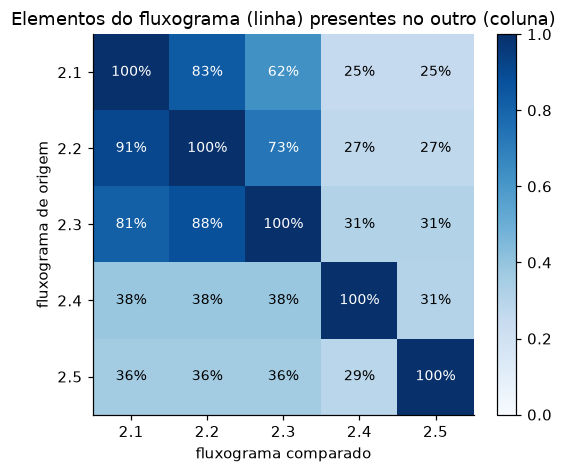

Famílias (≥ 80% em pelo menos um sentido): [['2.1', '2.2', '2.3'], ['2.4'], ['2.5']]
Casos independentes (uma por família): 3 de 5


In [23]:
LIM_DUP = 0.85


def frac_similar(a, b, lim=LIM_DUP):
    nb = [norm(e['nome']) for e in b['elementos']]
    acertos = sum(any(SequenceMatcher(None, norm(e['nome']), x).ratio() >= lim for x in nb) for e in a['elementos'])
    return acertos / len(a['elementos'])


codigos = [codigo(g) for g in gabaritos.values()]
sim = pd.DataFrame([[frac_similar(a, b) for b in gabaritos.values()] for a in gabaritos.values()], index=codigos, columns=codigos)

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(sim.values, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(len(codigos)), codigos)
ax.set_yticks(range(len(codigos)), codigos)
for i in range(len(codigos)):
    for j in range(len(codigos)):
        ax.text(j, i, f'{sim.values[i, j]:.0%}', ha='center', va='center', color='white' if sim.values[i, j] > 0.55 else 'black', fontsize=9)
ax.set_title('Elementos do fluxograma (linha) presentes no outro (coluna)')
ax.set_xlabel('fluxograma comparado')
ax.set_ylabel('fluxograma de origem')
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.show()

LIM_FAMILIA = 0.80
pai = {c: c for c in codigos}


def raiz_(c):
    while pai[c] != c:
        pai[c] = pai[pai[c]]
        c = pai[c]
    return c


for i, a in enumerate(codigos):
    for b in codigos[i + 1:]:
        if max(sim.loc[a, b], sim.loc[b, a]) >= LIM_FAMILIA:
            pai[raiz_(a)] = raiz_(b)
_grupos = {}
for c in codigos:
    _grupos.setdefault(raiz_(c), []).append(c)
familias = list(_grupos.values())
print('Famílias (≥ 80% em pelo menos um sentido):', familias)
print(f'Casos independentes (uma por família): {len(familias)} de {len(codigos)}')

### 4. Cobertura e representatividade
*(linha "Cobertura e representatividade")*

Quanto do universo de serviços o corpus cobre, e quais raias e sistemas aparecem.

In [33]:
presenca = (elementos.groupby(['raia', 'codigo']).size().unstack(fill_value=0))
presenca['em_quantos_fluxogramas'] = (presenca > 0).sum(axis=1)
presenca['total_de_passos'] = presenca.drop(columns='em_quantos_fluxogramas').sum(axis=1)
presenca = presenca.sort_values(['em_quantos_fluxogramas', 'total_de_passos'], ascending=False)
presenca

codigo,2.1,2.2,2.3,2.4,2.5,em_quantos_fluxogramas,total_de_passos
raia,,,,,,,
Requerente,6,6,5,2,4,5,23
SDU: Protocolo,6,6,4,2,2,5,20
SDU: CEU - AAD,5,5,3,3,2,5,18
SDU: CEU,2,2,2,2,2,5,10
SDU: CEU - DAP,3,3,2,2,0,4,10
SEMPLAN: SEPLUR - CTM,0,0,0,0,4,1,4
PRODATER: CAST,0,0,0,2,0,1,2
SDU: CECF,2,0,0,0,0,1,2


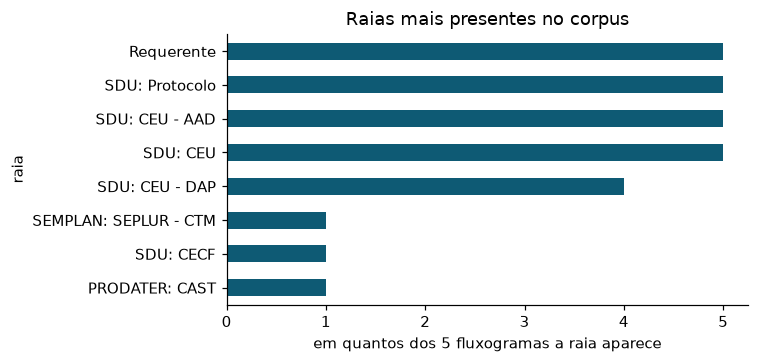

Sistemas citados: ['CAST (cast.prodater.pmt.pi.gov.br)', 'Plataforma SEI', 'SEI (sei.pmt.pi.gov.br/sei)']


In [25]:
ax = presenca['em_quantos_fluxogramas'].sort_values().plot.barh(figsize=(7, 3.4), color='#0E5A74')
ax.set_xlabel(f'em quantos dos {len(gabaritos)} fluxogramas a raia aparece')
ax.set_title('Raias mais presentes no corpus')
plt.tight_layout()
plt.show()

sistemas = sorted({s for g in gabaritos.values() for e in g['elementos'] for s in e['sistemas']} | {s for g in gabaritos.values() for s in g['gabarito']['sistema']})
print('Sistemas citados:', sistemas)

### 5. Desbalanceamento
*(linha "Desbalanceamento")*

Não há classes para balancear. O desequilíbrio é de **tamanho** e de **tipo de desvio**.

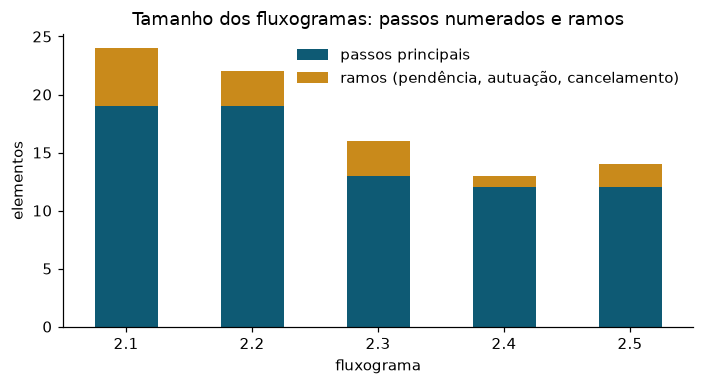

Tipos de ramo:


ramo,autuacao,cancelamento,pendencia
codigo,,,
2.1,2,0,3
2.2,0,0,3
2.3,0,0,3
2.4,0,1,0
2.5,0,0,2


In [26]:
tam = resumo[['passos_principais', 'ramos']]
ax = tam.plot.bar(stacked=True, figsize=(6.5, 3.6), color=['#0E5A74', '#C98A1B'])
ax.set_ylabel('elementos')
ax.set_xlabel('fluxograma')
ax.set_title('Tamanho dos fluxogramas: passos numerados e ramos')
ax.legend(['passos principais', 'ramos (pendência, autuação, cancelamento)'], frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print('Tipos de ramo:')
elementos[elementos['ramo'] != ''].groupby(['codigo', 'ramo']).size().unstack(fill_value=0)

### 6. Vieses identificados
*(linha "Vieses identificados")*

Viés de **domínio** (uma só coordenação, urbanismo) e de **padronização** (os fluxogramas repetem o mesmo esqueleto). Duas medidas simples:

In [27]:
norm_nome = elementos['nome'].map(norm)
em_quantos = elementos.assign(n=norm_nome).groupby('n')['codigo'].nunique()
repetidos = em_quantos[em_quantos >= 2].sort_values(ascending=False)
frac_repetidos = (norm_nome.isin(repetidos.index)).mean()
print(f'{frac_repetidos:.0%} dos elementos têm texto idêntico em pelo menos 2 fluxogramas.')
top = repetidos.head(8).rename('em quantos fluxogramas').to_frame()
top.index.name = 'texto normalizado'
display(top)

sdu = elementos['raia'].str.startswith('SDU').mean()
externa = elementos['raia'].isin(['Requerente']).mean()
print(f'Elementos em raias da SDU: {sdu:.0%}; em raia do requerente: {externa:.0%}; em outros órgãos: {1 - sdu - externa:.0%}.')

73% dos elementos têm texto idêntico em pelo menos 2 fluxogramas.


,em quantos fluxogramas
texto normalizado,
distribui processo a assessoria de apoio a divisao aad,5
solicitacao atraves da plataforma sei,5
encaminha processo a divisao de analise de projetos dap,4
conclui o processo,4
caso nao possua nenhuma pendencia o processo segue para deferimento,4
encerra o processo,4
retorna o processo para analise,4
caso seja notificado o solicitante deve resolver a pendencia,3


Elementos em raias da SDU: 67%; em raia do requerente: 26%; em outros órgãos: 7%.


### 7. Acesso, sigilo e privacidade
*(linha "Acesso, sigilo e privacidade")*

Procura padrões de dado pessoal nos JSON (CPF, e-mail, telefone) e nomes proibidos, e confere que **nenhum PDF** está no repositório.

In [30]:
PADROES = {'CPF': r'\b\d{3}\.?\d{3}\.?\d{3}-?\d{2}\b', 'e-mail': r'[\w.+-]+@[\w-]+\.[\w.-]+', 'telefone': r'\(?\b\d{2}\)?\s?9?\d{4}-?\d{4}\b'}

def textos(obj):
    if isinstance(obj, str):
        yield obj
    elif isinstance(obj, dict):
        for v in obj.values():
            yield from textos(v)
    elif isinstance(obj, list):
        for v in obj:
            yield from textos(v)


achados = []
for nome, g in gabaritos.items():
    for t in textos(g):
        for tipo, rx in PADROES.items():
            if re.search(rx, t):
                achados.append((nome, tipo, t[:60]))

pdfs = sorted(str(p.relative_to(RAIZ)) for p in RAIZ.rglob('*.pdf'))
print(f'Ocorrências de dados pessoais nos JSON: {len(achados)}', achados or '')
print(f'PDFs no repositório: {len(pdfs)}', pdfs or '')

Ocorrências de dados pessoais nos JSON: 0 
PDFs no repositório: 0 
